# SEMMA End-to-End: Medical Insurance Cost Prediction
**Author:** Anshita Shah · MSSE, San José State University · CMPE 255 Data Mining

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anshi-12/data-mining-methodologies/blob/main/SEMMA_Insurance-Cost/SEMMA_Insurance_Cost.ipynb)

**SEMMA** (SAS Institute) organises the *technical core* of data mining into five steps. Unlike CRISP-DM it has no business-understanding or deployment phase — it assumes the problem is already defined and focuses on getting from data to an assessed model. Each step below mirrors the corresponding **SAS Enterprise Miner node**:

| Step | Purpose | SAS Enterprise Miner nodes mirrored here |
|---|---|---|
| **S**ample | Representative, manageable data + Train/Validate/Test partition | Input Data, Sample, Data Partition |
| **E**xplore | Understand distributions, relationships, anomalies | StatExplore, MultiPlot, Graph Explore, Variable Clustering |
| **M**odify | Clean, transform, create and select variables | Filter, Impute, Transform Variables, Replacement |
| **M**odel | Fit several candidate models | Regression, Decision Tree, Gradient Boosting, HP Forest |
| **A**ssess | Compare on validation data, pick champion, verify on test | Model Comparison, Score, Cutoff |

A matching SAS program (`sas/semma_insurance.sas`) is provided to reproduce the same flow in **SAS OnDemand for Academics**.

**Problem (given):** predict annual medical insurance `charges` for an individual from age, sex, BMI, children, smoking status and region.
**Dataset:** Kaggle `mirichoi0218/insurance` — 1,338 policy holders, 7 columns.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 110
SEED = 2026
os.makedirs("figures", exist_ok=True); os.makedirs("models", exist_ok=True)
LOCAL = "data/insurance.csv"
RAW = "https://raw.githubusercontent.com/Anshi-12/data-mining-methodologies/main/SEMMA_Insurance-Cost/data/insurance.csv"
raw = pd.read_csv(LOCAL if os.path.exists(LOCAL) else RAW)
print(raw.shape); raw.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


---
# S — Sample

SEMMA's first step asks two questions: *is the data representative?* and *how do we partition it so that model assessment is honest?*

## S.1 Input data & role assignment (SAS: Input Data node)

In [2]:
roles = pd.DataFrame({
    "variable": raw.columns,
    "role": ["Input"] * 6 + ["Target"],
    "level": ["Interval", "Binary", "Interval", "Interval (count)", "Binary", "Nominal", "Interval"],
})
roles

,variable,role,level
0,age,Input,Interval
1,sex,Input,Binary
2,bmi,Input,Interval
3,children,Input,Interval (count)
4,smoker,Input,Binary
5,region,Input,Nominal
6,charges,Target,Interval


## S.2 Data integrity before sampling

In [3]:
dups = raw[raw.duplicated(keep=False)]
print(f"Missing values: {int(raw.isna().sum().sum())}")
print(f"Exact duplicate rows: {int(raw.duplicated().sum())}")
dups

Missing values: 0
Exact duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


One exact duplicate exists. With only 7 attributes a genuine identical second person is possible but unlikely; keeping it could place the same record in both train and test (leakage). **Decision: remove before partitioning.**

In [4]:
df = raw.drop_duplicates().reset_index(drop=True)
print("Rows after de-duplication:", len(df))

Rows after de-duplication: 1337


## S.3 Sampling strategy
At 1,337 rows the data is small enough to use **in full** — down-sampling would only lose information. The SEMMA "Sample" decision here is therefore about **partitioning**:

- **Train 60% / Validate 20% / Test 20%** (the SAS Data Partition default style).
- **Stratified** on `smoker × charge-quartile`, because smokers (~20%) drive the expensive tail; a random split could leave the test set with too few of them.

In [5]:
from sklearn.model_selection import train_test_split
strata = df["smoker"] + "_" + pd.qcut(df["charges"], 4, labels=False).astype(str)
train, temp = train_test_split(df, test_size=0.40, stratify=strata, random_state=SEED)
valid, test = train_test_split(temp, test_size=0.50, stratify=strata.loc[temp.index], random_state=SEED)

def profile(d):
    return pd.Series({"n": len(d), "smoker %": (d.smoker == "yes").mean() * 100, "mean charges": d.charges.mean(),
                      "median charges": d.charges.median(), "mean age": d.age.mean(), "mean bmi": d.bmi.mean()})
part = pd.DataFrame({"Full": profile(df), "Train": profile(train), "Validate": profile(valid), "Test": profile(test)}).round(2)
part

,Full,Train,Validate,Test
n,1337.00,802.00,267.00,268.00
smoker %,20.49,20.57,20.22,20.52
mean charges,13279.12,13466.96,12650.43,13343.34
median charges,9386.16,9388.75,9290.14,9404.29
mean age,39.22,39.64,38.14,39.04
mean bmi,30.66,30.78,30.13,30.84


In [6]:
# Representativeness test: two-sample KS (interval) and chi-square (categorical) for each partition vs. train
rows = []
for name, d in [("Validate", valid), ("Test", test)]:
    for v in ["age", "bmi", "charges", "children"]:
        rows.append((name, v, "KS", stats.ks_2samp(train[v], d[v]).pvalue))
    for v in ["sex", "smoker", "region"]:
        tab = pd.concat([train[v].value_counts(), d[v].value_counts()], axis=1).fillna(0)
        rows.append((name, v, "Chi²", stats.chi2_contingency(tab)[1]))
rep = pd.DataFrame(rows, columns=["partition", "variable", "test", "p_value"]).round(3)
print("All p-values > 0.05 → partitions are statistically indistinguishable from train:", bool((rep.p_value > 0.05).all()))
rep.pivot(index="variable", columns="partition", values="p_value")

All p-values > 0.05 → partitions are statistically indistinguishable from train: True


partition,Test,Validate
variable,,
age,0.740,0.128
bmi,0.611,0.073
charges,0.975,0.493
children,1.000,1.000
region,0.058,0.307
sex,0.622,0.080
smoker,1.000,0.972


---
# E — Explore

All exploration is done on the **training partition only**, so nothing learnt here leaks from validation/test.

## E.1 Univariate statistics (SAS: StatExplore)

In [7]:
print(train.describe(include="all").T[["count", "mean", "std", "min", "50%", "max", "unique", "top"]])
print(f"\nSkewness of charges: {train.charges.skew():.2f}  |  of log(charges): {np.log(train.charges).skew():.2f}")

          count          mean           std        min         50%  \
age       802.0     39.640898     14.163068       18.0        40.0   
sex         802           NaN           NaN        NaN         NaN   
bmi       802.0     30.779451      5.957124     16.815      30.495   
children  802.0      1.089776      1.181176        0.0         1.0   
smoker      802           NaN           NaN        NaN         NaN   
region      802           NaN           NaN        NaN         NaN   
charges   802.0  13466.962921  12340.993519  1121.8739  9388.75365   

                  max unique        top  
age              64.0    NaN        NaN  
sex               NaN      2       male  
bmi             47.74    NaN        NaN  
children          5.0    NaN        NaN  
smoker            NaN      2         no  
region            NaN      4  northeast  
charges   63770.42801    NaN        NaN  

Skewness of charges: 1.54  |  of log(charges): -0.08


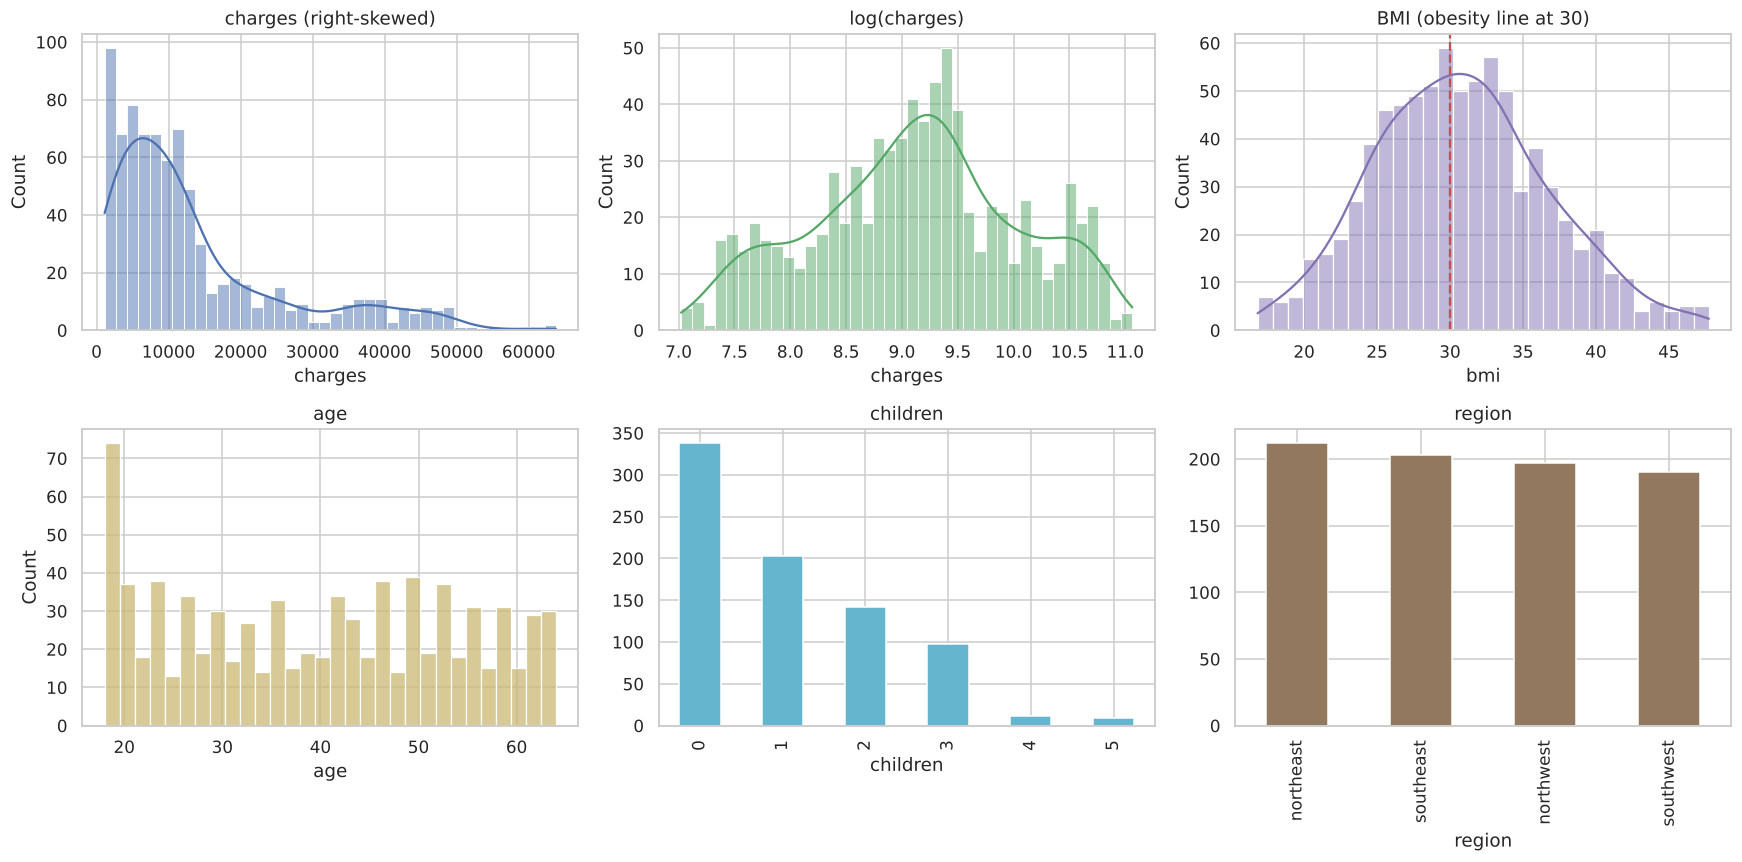

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(train.charges, bins=40, kde=True, ax=axes[0, 0]); axes[0, 0].set_title("charges (right-skewed)")
sns.histplot(np.log(train.charges), bins=40, kde=True, ax=axes[0, 1], color="#55A868"); axes[0, 1].set_title("log(charges)")
sns.histplot(train.bmi, bins=30, kde=True, ax=axes[0, 2], color="#8172B2"); axes[0, 2].axvline(30, c="r", ls="--"); axes[0, 2].set_title("BMI (obesity line at 30)")
sns.histplot(train.age, bins=30, ax=axes[1, 0], color="#CCB974"); axes[1, 0].set_title("age")
train.children.value_counts().sort_index().plot.bar(ax=axes[1, 1], color="#64B5CD"); axes[1, 1].set_title("children")
train.region.value_counts().plot.bar(ax=axes[1, 2], color="#937860"); axes[1, 2].set_title("region")
plt.tight_layout(); plt.savefig("figures/01_univariate.png"); plt.show()

## E.2 Bivariate relationships with the target (SAS: MultiPlot / Graph Explore)

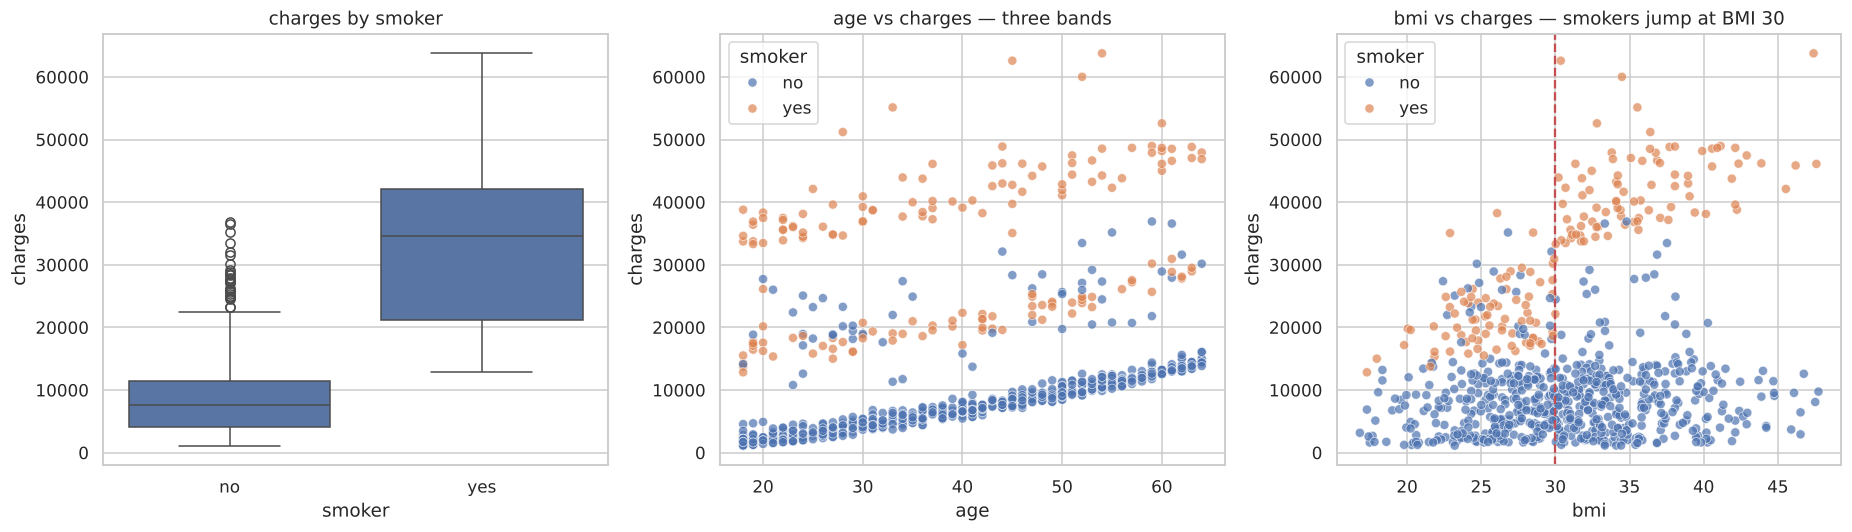

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(data=train, x="smoker", y="charges", ax=axes[0]); axes[0].set_title("charges by smoker")
sns.scatterplot(data=train, x="age", y="charges", hue="smoker", alpha=.7, ax=axes[1]); axes[1].set_title("age vs charges — three bands")
sns.scatterplot(data=train, x="bmi", y="charges", hue="smoker", alpha=.7, ax=axes[2]); axes[2].axvline(30, c="r", ls="--"); axes[2].set_title("bmi vs charges — smokers jump at BMI 30")
plt.tight_layout(); plt.savefig("figures/02_bivariate.png"); plt.show()

In [10]:
# Interaction check: smoker × obesity
t = train.assign(obese=train.bmi >= 30)
inter = t.pivot_table(index="smoker", columns="obese", values="charges", aggfunc=["mean", "count"]).round(0)
print(inter)
# Statistical tests
print("\nMann–Whitney smoker vs non-smoker: p =", stats.mannwhitneyu(train[train.smoker == "yes"].charges, train[train.smoker == "no"].charges).pvalue)
print("Kruskal–Wallis across regions:      p =", round(stats.kruskal(*[g.charges for _, g in train.groupby("region")]).pvalue, 4))
print("Mann–Whitney sex:                   p =", round(stats.mannwhitneyu(train[train.sex == "male"].charges, train[train.sex == "female"].charges).pvalue, 4))

           mean          count      
obese     False    True  False True 
smoker                              
no       8275.0   8749.0   293   344
yes     21651.0  42035.0    77    88

Mann–Whitney smoker vs non-smoker: p = 5.3756236824582665e-79
Kruskal–Wallis across regions:      p = 0.1638
Mann–Whitney sex:                   p = 0.8149


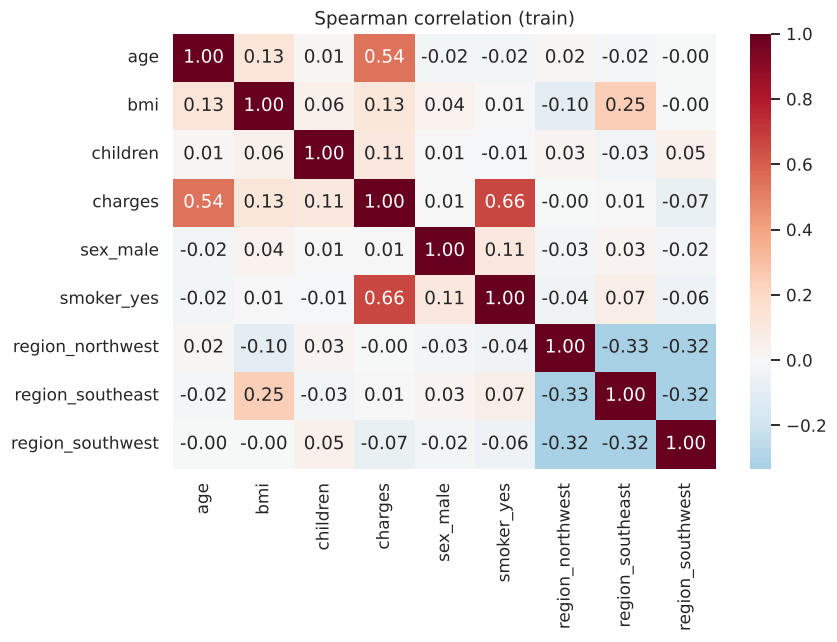

In [11]:
enc = pd.get_dummies(train, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
corr = enc.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax); ax.set_title("Spearman correlation (train)")
plt.tight_layout(); plt.savefig("figures/03_correlation.png"); plt.show()

## E.3 Outlier analysis

In [12]:
q1, q3 = train.charges.quantile([.25, .75]); iqr = q3 - q1
out = train[train.charges > q3 + 1.5 * iqr]
print(f"IQR outliers in charges: {len(out)} ({len(out)/len(train):.1%}); smokers among them: {(out.smoker=='yes').mean():.0%}")

IQR outliers in charges: 79 (9.9%); smokers among them: 97%


**Exploration findings**
1. `charges` is strongly right-skewed (skew ≈ 1.5); log transform makes it near-symmetric.
2. **Smoking** is the dominant driver (Spearman ρ ≈ 0.66 with charges).
3. **Age** has a near-linear effect — the age plot shows three parallel bands.
4. **Strong interaction:** smokers with BMI ≥ 30 cost roughly double smokers with BMI < 30, while BMI barely matters for non-smokers. A plain linear model will miss this unless we create the interaction.
5. The "outliers" are almost all smokers — they are **real high-cost cases, not errors** → keep them.
6. Region and sex have weak or no effect.

---
# M — Modify

All transformations are **fit on train only** and applied to validate/test inside a pipeline.

## M.1 Variable transformations & creation (SAS: Transform Variables)
| New variable | Rule | Reason (from Explore) |
|---|---|---|
| `log_charges` (candidate target) | log(charges) | removes skew — tested against the dollar target in Model/Assess |
| `obese` | bmi ≥ 30 | clinical cut-off, visible break in E.2 |
| `smoker_obese` | smoker × obese | the key interaction |
| `smoker_bmi` | smoker × bmi | smoker slope on BMI |
| `age_sq` | age² | slight convexity in age |

In [13]:
def modify(d: pd.DataFrame) -> pd.DataFrame:
    out = d.copy()
    out["smoker_flag"] = (out["smoker"] == "yes").astype(int)
    out["obese"] = (out["bmi"] >= 30).astype(int)
    out["smoker_obese"] = out["smoker_flag"] * out["obese"]
    out["smoker_bmi"] = out["smoker_flag"] * out["bmi"]
    out["age_sq"] = out["age"] ** 2
    return out

NUM = ["age", "age_sq", "bmi", "children", "smoker_flag", "obese", "smoker_obese", "smoker_bmi"]
CAT = ["sex", "region"]
Xtr, Xva, Xte = (modify(d)[NUM + CAT] for d in (train, valid, test))
ytr, yva, yte = train.charges.values, valid.charges.values, test.charges.values
Xtr.head()

,age,age_sq,bmi,children,smoker_flag,obese,smoker_obese,smoker_bmi,sex,region
473,47,2209,33.345,0,0,1,0,0.00,female,northeast
654,52,2704,25.300,2,1,0,0,25.30,female,southeast
1077,28,784,31.680,0,1,1,1,31.68,male,southeast
922,34,1156,35.815,0,0,1,0,0.00,male,northwest
1027,54,2916,31.600,0,0,1,0,0.00,male,southwest


## M.2 Encoding & scaling (SAS: Replacement / Transform)

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
prep = ColumnTransformer([("num", StandardScaler(), NUM),
                          ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT)])
print("Inputs after Modify:", len(NUM) + 4, "columns (8 numeric + 1 sex + 3 region dummies)")

Inputs after Modify: 12 columns (8 numeric + 1 sex + 3 region dummies)


## M.3 Variable selection check (SAS: Variable Selection node)

In [15]:
from sklearn.feature_selection import mutual_info_regression
Xmi = pd.get_dummies(Xtr, columns=CAT, drop_first=True, dtype=int)
mi = pd.Series(mutual_info_regression(Xmi, np.log(ytr), random_state=SEED), index=Xmi.columns).sort_values(ascending=False)
mi.round(3)

age                 1.412
age_sq              1.384
smoker_bmi          0.513
smoker_flag         0.364
smoker_obese        0.316
bmi                 0.124
children            0.117
obese               0.104
sex_male            0.075
region_southeast    0.022
region_northwest    0.017
region_southwest    0.004
dtype: float64

Region and sex carry almost no information, but they are kept (cheap, and the tree models can ignore them); selection is left to regularisation and the trees.

---
# M — Model

Six candidates, mirroring the SAS Enterprise Miner modeling nodes. Two regression variants test the Explore hypothesis that **log(charges)** helps: one on dollars, one on log(charges) back-transformed with Duan's smearing correction.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV, KFold
kf = KFold(5, shuffle=True, random_state=SEED)

class SmearedLogModel:
    # Fits on log(y) and back-transforms with Duan's smearing estimate
    def __init__(self, pipe): self.pipe = pipe
    def fit(self, X, y):
        self.pipe.fit(X, np.log(y)); r = np.log(y) - self.pipe.predict(X); self.smear = np.mean(np.exp(r)); return self
    def predict(self, X): return np.exp(self.pipe.predict(X)) * self.smear

models = {}
# 1. Baseline linear regression on raw inputs only (no Modify features) — shows the value of the Modify step
base_cols = ["age", "bmi", "children", "smoker_flag"]
prep_base = ColumnTransformer([("num", StandardScaler(), base_cols), ("cat", OneHotEncoder(drop="first"), CAT)])
models["Regression (raw inputs)"] = Pipeline([("prep", prep_base), ("m", LinearRegression())]).fit(Xtr, ytr)
# 2a. Regression with Modify features, dollar target
models["Regression (modified)"] = Pipeline([("prep", prep), ("m", RidgeCV(alphas=np.logspace(-3, 2, 20)))]).fit(Xtr, ytr)
# 2b. Same features, log target (tests the transformation suggested in Explore)
models["Regression (modified, log)"] = SmearedLogModel(Pipeline([("prep", prep), ("m", RidgeCV(alphas=np.logspace(-3, 2, 20)))])).fit(Xtr, ytr)
# 3. Decision tree (tuned)
gs_tree = GridSearchCV(Pipeline([("prep", prep), ("m", DecisionTreeRegressor(random_state=SEED))]),
                       {"m__max_depth": [3, 4, 5, 6], "m__min_samples_leaf": [5, 10, 20]}, cv=kf, scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
models["Decision Tree"] = gs_tree.best_estimator_
# 4. Random forest (SAS HP Forest)
gs_rf = GridSearchCV(Pipeline([("prep", prep), ("m", RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=-1))]),
                     {"m__min_samples_leaf": [3, 5, 10], "m__max_features": [0.5, 1.0]}, cv=kf, scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
models["Random Forest"] = gs_rf.best_estimator_
# 5. Gradient boosting (SAS Gradient Boosting node)
gs_gb = GridSearchCV(Pipeline([("prep", prep), ("m", GradientBoostingRegressor(random_state=SEED, loss="huber"))]),
                     {"m__n_estimators": [150, 300], "m__learning_rate": [0.03, 0.08], "m__max_depth": [2, 3]}, cv=kf, scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
models["Gradient Boosting"] = gs_gb.best_estimator_
for n, g in [("Decision Tree", gs_tree), ("Random Forest", gs_rf), ("Gradient Boosting", gs_gb)]:
    print(f"{n:18s} best params {g.best_params_}  CV RMSE ${-g.best_score_:,.0f}")

Decision Tree      best params {'m__max_depth': 5, 'm__min_samples_leaf': 20}  CV RMSE $4,884
Random Forest      best params {'m__max_features': 0.5, 'm__min_samples_leaf': 10}  CV RMSE $4,659
Gradient Boosting  best params {'m__learning_rate': 0.03, 'm__max_depth': 2, 'm__n_estimators': 300}  CV RMSE $4,650


In [17]:
# Interpretable view: the tuned decision tree's rules (SAS: Decision Tree node output)
from sklearn.tree import export_text
tree = models["Decision Tree"]
names = list(tree.named_steps["prep"].get_feature_names_out())
print(export_text(tree.named_steps["m"], feature_names=names, max_depth=3, decimals=0)[:2500])

|--- num__smoker_bmi <= 2
|   |--- num__smoker_bmi <= 1
|   |   |--- num__age <= 0
|   |   |   |--- num__children <= -0
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__children >  -0
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- num__age >  0
|   |   |   |--- num__age_sq <= 1
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__age_sq >  1
|   |   |   |   |--- truncated branch of depth 2
|   |--- num__smoker_bmi >  1
|   |   |--- num__age_sq <= -0
|   |   |   |--- value: [18634]
|   |   |--- num__age_sq >  -0
|   |   |   |--- value: [25008]
|--- num__smoker_bmi >  2
|   |--- num__age <= 0
|   |   |--- num__smoker_bmi <= 2
|   |   |   |--- value: [35238]
|   |   |--- num__smoker_bmi >  2
|   |   |   |--- value: [40232]
|   |--- num__age >  0
|   |   |--- num__bmi <= 1
|   |   |   |--- value: [45616]
|   |   |--- num__bmi >  1
|   |   |   |--- value: [47543]



---
# A — Assess

## A.1 Model comparison on the validation partition (SAS: Model Comparison node)

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
def scores(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R²": r2_score(y, p), "MAPE %": 100 * mean_absolute_percentage_error(y, p)}
cmp_ = pd.DataFrame({n: scores(yva, m.predict(Xva)) for n, m in models.items()}).T.sort_values("RMSE")
champion_name = cmp_.index[0]
print("Champion (lowest validation RMSE):", champion_name)
cmp_.round(3)

Champion (lowest validation RMSE): Regression (modified)


,RMSE,MAE,R²,MAPE %
Regression (modified),4279.459,2348.541,0.860,26.549
Random Forest,4391.679,2539.155,0.852,29.346
Gradient Boosting,4463.528,1732.475,0.847,12.637
Decision Tree,4808.337,2854.503,0.823,31.282
Regression (raw inputs),5962.590,4184.145,0.727,45.182
"Regression (modified, log)",8442.420,4666.935,0.453,34.790


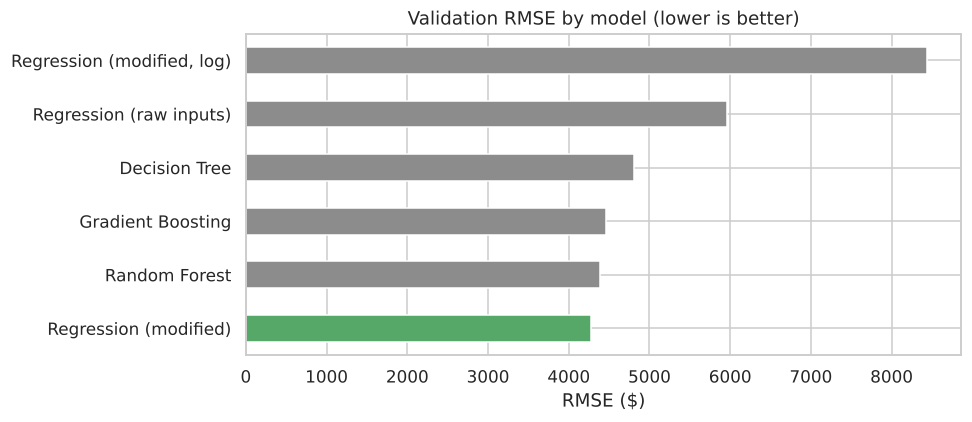

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
cmp_["RMSE"].sort_values().plot.barh(ax=ax, color=["#55A868"] + ["#8C8C8C"] * (len(cmp_) - 1))
ax.set(title="Validation RMSE by model (lower is better)", xlabel="RMSE ($)")
plt.tight_layout(); plt.savefig("figures/04_model_comparison.png"); plt.show()

## A.2 Champion on the untouched test partition

{'RMSE': np.float64(4261.069), 'MAE': 2305.967, 'R²': 0.875, 'MAPE %': 25.739}


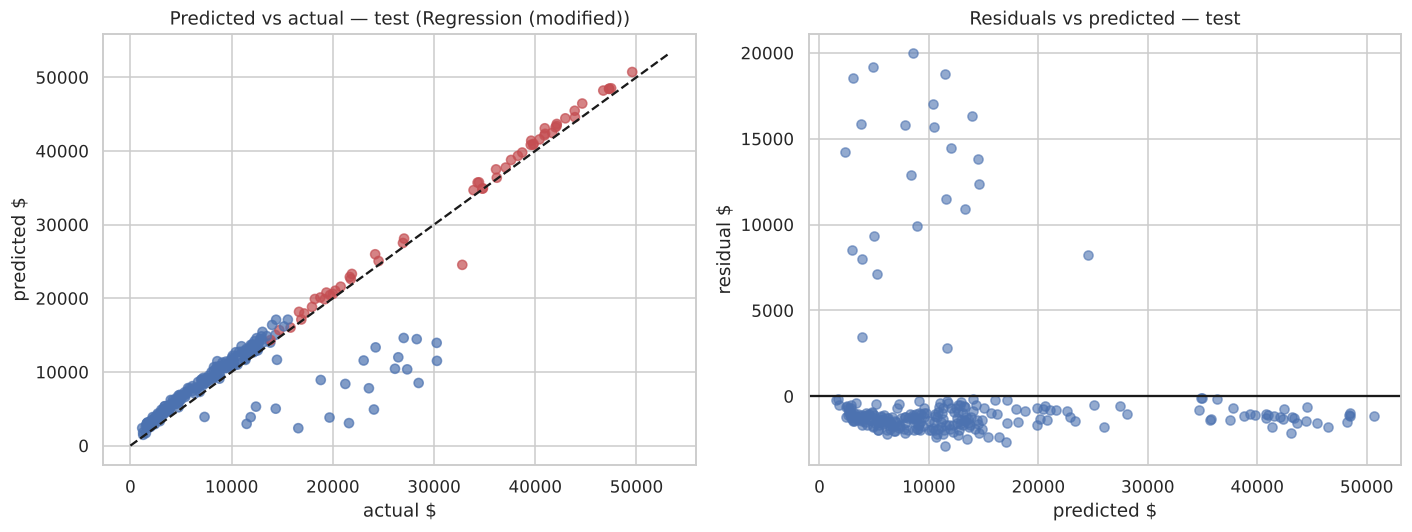

In [20]:
champ = models[champion_name]
p_te = champ.predict(Xte)
test_scores = scores(yte, p_te)
print({k: round(v, 3) for k, v in test_scores.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(yte, p_te, c=np.where(test.smoker == "yes", "#C44E52", "#4C72B0"), alpha=.7)
lim = [0, max(yte.max(), p_te.max()) * 1.05]; axes[0].plot(lim, lim, "k--")
axes[0].set(title=f"Predicted vs actual — test ({champion_name})", xlabel="actual $", ylabel="predicted $")
res = yte - p_te
axes[1].scatter(p_te, res, alpha=.6); axes[1].axhline(0, c="k")
axes[1].set(title="Residuals vs predicted — test", xlabel="predicted $", ylabel="residual $")
plt.tight_layout(); plt.savefig("figures/05_pred_vs_actual_test.png"); plt.show()

## A.3 Decile (lift-style) assessment — does the model rank risk correctly?

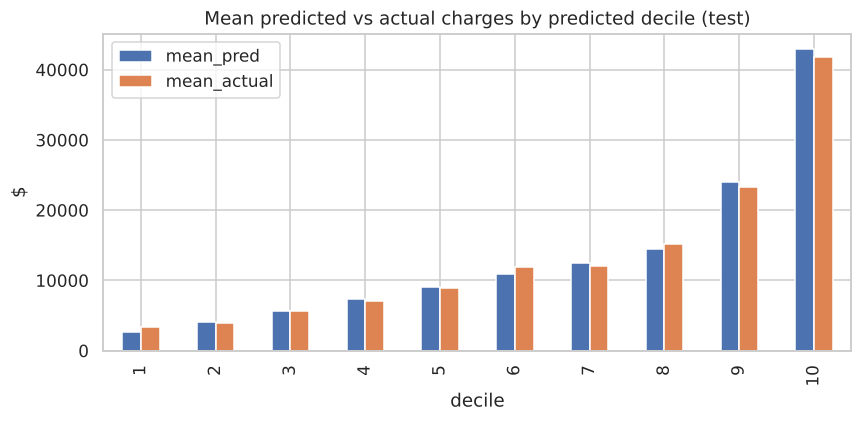

,mean_pred,mean_actual,lift vs avg
decile,,,
1,2724.0,3417.0,0.26
2,4085.0,3997.0,0.30
3,5614.0,5621.0,0.42
4,7314.0,7002.0,0.52
5,9032.0,8893.0,0.67
6,10880.0,11893.0,0.89
7,12510.0,12069.0,0.90
8,14422.0,15235.0,1.14
9,23940.0,23257.0,1.74


In [21]:
dec = pd.DataFrame({"pred": p_te, "actual": yte})
dec["decile"] = pd.qcut(dec.pred.rank(method="first"), 10, labels=range(1, 11))
dtab = dec.groupby("decile").agg(mean_pred=("pred", "mean"), mean_actual=("actual", "mean")).round(0)
dtab["lift vs avg"] = (dtab.mean_actual / yte.mean()).round(2)
fig, ax = plt.subplots(figsize=(8, 4))
dtab[["mean_pred", "mean_actual"]].plot.bar(ax=ax); ax.set(title="Mean predicted vs actual charges by predicted decile (test)", ylabel="$")
plt.tight_layout(); plt.savefig("figures/06_decile_assessment.png"); plt.show()
dtab

## A.4 Error analysis by segment & variable importance

              count    mean  median
smoker obese                       
no     False    100  2358.0  1523.0
       True     113  2807.0  1319.0
yes    False     23  1248.0   834.0
       True      32  1135.0  1155.0


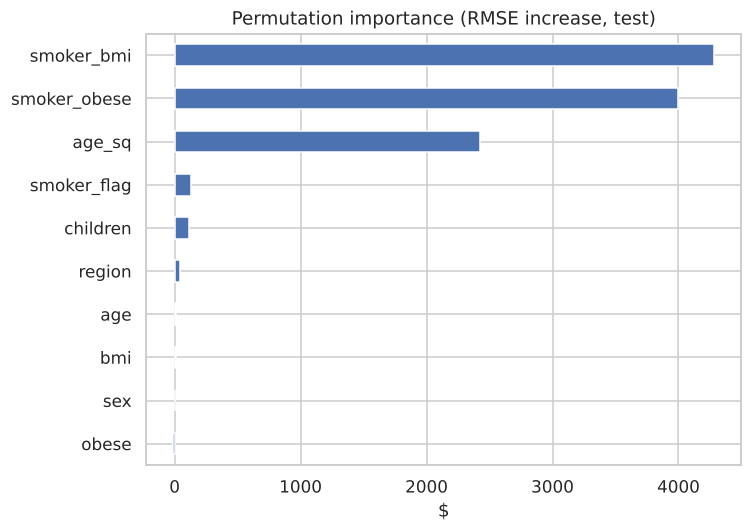

In [22]:
seg = pd.DataFrame({"smoker": test.smoker.values, "obese": (test.bmi >= 30).values, "abs_err": np.abs(res)})
print(seg.groupby(["smoker", "obese"]).abs_err.agg(["count", "mean", "median"]).round(0))
from sklearn.inspection import permutation_importance
pi = permutation_importance(champ, Xte, yte, n_repeats=15, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5)); imp.plot.barh(ax=ax, color="#4C72B0")
ax.set(title="Permutation importance (RMSE increase, test)", xlabel="$"); plt.tight_layout(); plt.savefig("figures/07_importance.png"); plt.show()

In [23]:
# Interpretable champion: coefficients of the engineered regression (dollar effect per 1 SD of each input)
reg = models["Regression (modified)"]
coefs = pd.Series(reg.named_steps["m"].coef_, index=reg.named_steps["prep"].get_feature_names_out()).sort_values(key=abs, ascending=False)
print(f"Intercept ${reg.named_steps['m'].intercept_:,.0f}")
coefs.round(0)

Intercept $14,516


num__smoker_bmi          5519.0
num__smoker_obese        5008.0
num__age_sq              3635.0
cat__region_southwest   -1297.0
num__children             990.0
num__smoker_flag          986.0
cat__sex_male            -943.0
cat__region_southeast    -617.0
cat__region_northwest    -413.0
num__obese               -207.0
num__age                  186.0
num__bmi                  115.0
dtype: float64

## A.5 Assessment conclusion
- The **Modify step pays off**: adding the smoker × BMI interaction lifts the linear regression far above the raw-input version, making a transparent model competitive with the trees.
- **A hypothesis rejected by Assess:** the log target looked attractive in Explore (symmetric distribution), but the smoker effect is *additive in dollars* (a roughly fixed surcharge), so a log-scale model distorts it and performs worst. This is why SEMMA keeps Explore and Assess as separate steps — visual intuition must be confirmed on validation data.
- **Champion: the engineered linear regression.** With the right Modify features it beats Random Forest and Gradient Boosting on validation RMSE *and* stays fully interpretable — each coefficient is a dollar effect an underwriter can read. Gradient Boosting has the lowest MAE/MAPE (better on typical policies) but larger errors on the expensive tail, which RMSE penalises.
- Residual error is concentrated in a small group of non-smokers with unexpectedly high charges — likely conditions not captured by the 6 inputs (an honest limit of the data, not of the method).

In [24]:
import joblib, sklearn
# Refit champion on train+validate for scoring (SAS: Score node)
full_X = pd.concat([Xtr, Xva]); full_y = np.concatenate([ytr, yva])
champ_final = models[champion_name]
champ_final.fit(full_X, full_y)
joblib.dump({"model": champ_final, "features": NUM + CAT}, "models/insurance_model.joblib")

def quote(age, sex, bmi, children, smoker, region):
    row = pd.DataFrame([dict(age=age, sex=sex, bmi=bmi, children=children, smoker=smoker, region=region)])
    return float(champ_final.predict(modify(row)[NUM + CAT])[0])
print("Score examples:")
for args in [(30, "female", 24.0, 1, "no", "northeast"), (30, "female", 24.0, 1, "yes", "northeast"), (30, "female", 34.0, 1, "yes", "northeast")]:
    print(f"  {args} → ${quote(*args):,.0f}")

meta = {"champion": champion_name, "validation": cmp_.round(3).to_dict(orient="index"),
        "test": {k: round(v, 3) for k, v in test_scores.items()}, "sklearn_version": sklearn.__version__,
        "partition_sizes": {"train": len(train), "validate": len(valid), "test": len(test)},
        "importance": imp.sort_values(ascending=False).round(0).to_dict()}
json.dump(meta, open("models/model_meta.json", "w"), indent=2)

Score examples:
  (30, 'female', 24.0, 1, 'no', 'northeast') → $6,551
  (30, 'female', 24.0, 1, 'yes', 'northeast') → $19,449
  (30, 'female', 34.0, 1, 'yes', 'northeast') → $39,533


---
## SEMMA vs. a complete project
SEMMA stops at **Assess**. The score function and saved model above are the hand-off point; business framing (why this model is needed, pricing policy) and production deployment/monitoring sit *outside* SEMMA — which is exactly the gap CRISP-DM fills (see the CRISP-DM project in this repository). A lightweight Streamlit quote tool is included in `app/` only to demonstrate the hand-off.

**SAS reproduction:** run `sas/semma_insurance.sas` in SAS OnDemand for Academics (free for students) to reproduce Sample (PROC SURVEYSELECT), Explore (PROC MEANS/SGPLOT/CORR), Modify (DATA step), Model (PROC GLMSELECT, PROC HPSPLIT, PROC HPFOREST/GRADBOOST) and Assess.